In [1]:
import re, unicodedata
import pandas as pd

df = pd.read_csv("imh_complaints.csv")
print(df.shape)
print(df["department"].value_counts())
df.head()

(40, 4)
department
Electricity    9
Water          8
Sanitation     7
Traffic        6
Health         6
Other          4
Name: count, dtype: int64


,ticket_id,department,complaint_text,gold_entities
0,IMH-001,Electricity,Bijli nahi aa rahi Sector G-9 Islamabad mein l...,Sector G-9|LOC; Islamabad|LOC; IESCO|ORG
1,IMH-002,Water,No water in Street 7 F-11 since Monday. CDA ta...,Street 7|LOC; F-11|LOC; Monday|DATE; CDA|ORG
2,IMH-003,Sanitation,Garbage has not been collected from I-8 Markaz...,I-8 Markaz|LOC; CDA|ORG
3,IMH-004,Electricity,The residents of G-9 submitted a complaint abo...,G-9|LOC
4,IMH-005,Traffic,Illegal parking in front of Centaurus Mall is ...,Centaurus Mall|LOC


In [2]:
def clean(text):
    # 1. Unicode normalise: ek hi character ki alag encodings ko ek form deta hai
    t = unicodedata.normalize("NFKC", text)
    # 2. URLs placeholder se replace
    t = re.sub(r"https?://\S+|www\.\S+", " urltok ", t)
    # 3. CNIC PEHLE (warna phone regex isko kha jata)
    t = re.sub(r"\b\d{5}-?\d{7}-?\d\b", " cnictok ", t)
    # 4. Pakistani mobile numbers (PII redaction)
    t = re.sub(r"(\+92|0)3\d{2}[-\s]?\d{7}", " phonetok ", t)
    # 5. Emojis hatao (noise hain)
    t = re.sub(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", " ", t)
    # 6. Lowercase: Roman Urdu mein case ka koi meaning nahi
    t = t.lower()
    # 7. g-10/3 -> g10_3 (PEHLE, warna agla rule isko tod dega)
    t = re.sub(r"\b([a-z])-(\d{1,2})/(\d)\b", r"\1\2_\3", t)
    # 8. g-9 -> g9, f-11 -> f11 (locality codes bachao)
    t = re.sub(r"\b([a-z])-(\d{1,2})\b", r"\1\2", t)
    # 9. Extra spaces saaf
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["complaint_text"].apply(clean)
df[["ticket_id", "complaint_text", "clean"]].head(10)

,ticket_id,complaint_text,clean
0,IMH-001,Bijli nahi aa rahi Sector G-9 Islamabad mein l...,bijli nahi aa rahi sector g9 islamabad mein la...
1,IMH-002,No water in Street 7 F-11 since Monday. CDA ta...,no water in street 7 f11 since monday. cda tan...
2,IMH-003,Garbage has not been collected from I-8 Markaz...,garbage has not been collected from i8 markaz ...
3,IMH-004,The residents of G-9 submitted a complaint abo...,the residents of g9 submitted a complaint abou...
4,IMH-005,Illegal parking in front of Centaurus Mall is ...,illegal parking in front of centaurus mall is ...
5,IMH-006,PIMS emergency waiting time was more than 4 ho...,pims emergency waiting time was more than 4 ho...
6,IMH-007,Pipe burst on Khayaban-e-Iqbal near Melody Foo...,pipe burst on khayaban-e-iqbal near melody foo...
7,IMH-008,Meter reader from IESCO overcharged our house ...,meter reader from iesco overcharged our house ...
8,IMH-009,Sewerage overflow outside Faisal Mosque parkin...,sewerage overflow outside faisal mosque parkin...
9,IMH-010,Please tell me how to apply for a new commerci...,please tell me how to apply for a new commerci...


In [3]:
# G-10/3 wali ticket poori dekho (IMH-008 = index 7)
print(df.loc[7, "complaint_text"])
print(df.loc[7, "clean"])

# PII demo: dataset mein phone/CNIC/URL/emoji nahi, isliye khud ke 3 examples
demo = [
    "Bijli band hai, call 0300-1234567 ya CNIC 61101-1234567-1 😡",
    "Details: https://example.com/complaint?id=9 G-9 mein pani nahi",
    "Meter reading galat hai ⚡ IESCO ko 03451234567 par call kiya",
]
for d in demo:
    print("\nBEFORE:", d)
    print("AFTER :", clean(d))

Meter reader from IESCO overcharged our house in G-10/3. Bill is 45000 which is impossible.
meter reader from iesco overcharged our house in g10_3. bill is 45000 which is impossible.

BEFORE: Bijli band hai, call 0300-1234567 ya CNIC 61101-1234567-1 😡
AFTER : bijli band hai, call phonetok ya cnic cnictok

BEFORE: Details: https://example.com/complaint?id=9 G-9 mein pani nahi
AFTER : details: urltok g9 mein pani nahi

BEFORE: Meter reading galat hai ⚡ IESCO ko 03451234567 par call kiya
AFTER : meter reading galat hai iesco ko phonetok par call kiya


In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Dono ko same settings do (unigram + bigram) taake fark sirf weighting ka ho
bow = CountVectorizer(ngram_range=(1, 2))
tfidf = TfidfVectorizer(ngram_range=(1, 2))
X_bow = bow.fit_transform(df["clean"])    # har cell = word ki count
X_tf = tfidf.fit_transform(df["clean"])   # har cell = TF-IDF weight

for name, X in [("BoW", X_bow), ("TF-IDF", X_tf)]:
    n_docs, vocab = X.shape
    sparsity = 1 - X.nnz / (n_docs * vocab)   # nnz = non-zero entries ki ginti
    print(f"{name}: docs={n_docs}, vocab={vocab}, sparsity={sparsity:.4f}")

terms = tfidf.get_feature_names_out()

def top_terms(ticket_id, n=10):
    i = df.index[df.ticket_id == ticket_id][0]
    row = X_tf[i].toarray().ravel()
    idx = [j for j in row.argsort()[::-1][:n] if row[j] > 0]
    return [(terms[j], round(float(row[j]), 3)) for j in idx]

print("\nElectricity IMH-008:", top_terms("IMH-008"))
print("Water IMH-016:", top_terms("IMH-016"))

BoW: docs=40, vocab=902, sparsity=0.9690
TF-IDF: docs=40, vocab=902, sparsity=0.9690

Electricity IMH-008: [('reader from', 0.2), ('reader', 0.2), ('overcharged our', 0.2), ('overcharged', 0.2), ('meter reader', 0.2), ('our house', 0.2), ('which is', 0.2), ('which', 0.2), ('is impossible', 0.2), ('is 45000', 0.2)]
Water IMH-016: [('in f8', 0.191), ('muddy', 0.191), ('f8', 0.191), ('stomach pain', 0.191), ('stomach', 0.191), ('water from', 0.191), ('drinking water', 0.191), ('pain', 0.191), ('drinking', 0.191), ('plant in', 0.191)]


In [5]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

S = cosine_similarity(X_tf)   # 40x40 matrix, har ticket vs har ticket

def sim(a, b):
    i = df.index[df.ticket_id == a][0]
    j = df.index[df.ticket_id == b][0]
    return round(float(S[i, j]), 3)

print("Same dept (IMH-001 vs IMH-019, Electricity):", sim("IMH-001", "IMH-019"))
print("Same dept (IMH-002 vs IMH-011, Water):      ", sim("IMH-002", "IMH-011"))
print("Diff dept (IMH-001 vs IMH-009, Elec vs Sanit):", sim("IMH-001", "IMH-009"))

# .to_numpy() = plain numpy array, taake [:, None] (2D banana) chale
dept = df["department"].to_numpy()
same = dept[:, None] == dept[None, :]         # True jahan dono tickets ka dept same
off_diag = ~np.eye(len(df), dtype=bool)       # diagonal (ticket vs khud) nikaal do
print("Avg same-dept:", round(float(S[same & off_diag].mean()), 3))
print("Avg diff-dept:", round(float(S[~same].mean()), 3))

Same dept (IMH-001 vs IMH-019, Electricity): 0.034
Same dept (IMH-002 vs IMH-011, Water):       0.127
Diff dept (IMH-001 vs IMH-009, Elec vs Sanit): 0.0
Avg same-dept: 0.027
Avg diff-dept: 0.014


In [6]:
import os, json
os.makedirs("results", exist_ok=True)   # report/PPT ka sara data yahan jama hoga

def save_table(df_, name):
    df_.to_csv(f"results/{name}.csv", index=False)   # table CSV mein save

def save_note(key, value):
    path = "results/numbers.json"                    # chhote numbers ek hi JSON mein
    data = json.load(open(path)) if os.path.exists(path) else {}
    data[key] = value
    json.dump(data, open(path, "w"), indent=2)

In [7]:
save_note("A2_vocab_size", 902)
save_note("A2_sparsity", 0.9690)
save_note("A2_cos_same_IMH001_IMH019", 0.034)
save_note("A2_cos_same_IMH002_IMH011", 0.127)
save_note("A2_cos_diff_IMH001_IMH009", 0.0)
save_note("A2_avg_same_dept", 0.027)
save_note("A2_avg_diff_dept", 0.014)

demo_df = pd.DataFrame({"before": demo, "after": [clean(d) for d in demo]})
save_table(demo_df, "A1_demo_before_after")
print("saved")

saved


In [8]:
i = df.index[df.ticket_id == "IMH-001"][0]
j = df.index[df.ticket_id == "IMH-019"][0]
common = [terms[k] for k in range(len(terms)) if X_tf[i, k] > 0 and X_tf[j, k] > 0]
print(common)

['hours', 'iesco']


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

labels = sorted(df["department"].unique())   # fixed order, confusion matrix ke liye

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["department"],
    test_size=0.30,
    stratify=df["department"],   # har class ka ratio train/test dono mein barabar
    random_state=42)             # har run pe same split (reproducible)

models = {
    "NaiveBayes": Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
                            ("clf", MultinomialNB())]),
    "LinearSVM":  Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
                            ("clf", LinearSVC(random_state=42))]),
}
for m in models.values():
    m.fit(X_train, y_train)   # TF-IDF sirf train pe seekha jata hai (no leakage)

print("train:", len(X_train), "test:", len(X_test))
print(y_test.value_counts())

train: 28 test: 12
department
Electricity    3
Traffic        2
Health         2
Water          2
Sanitation     2
Other          1
Name: count, dtype: int64


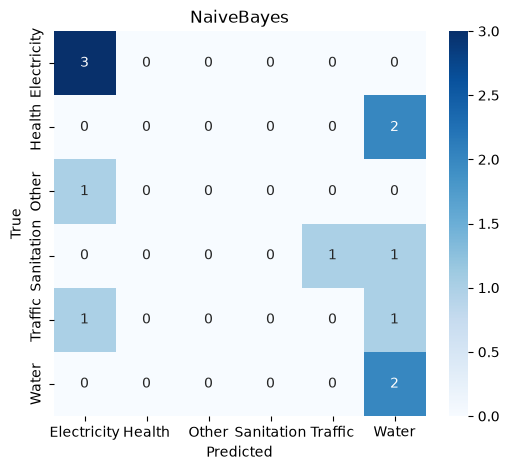

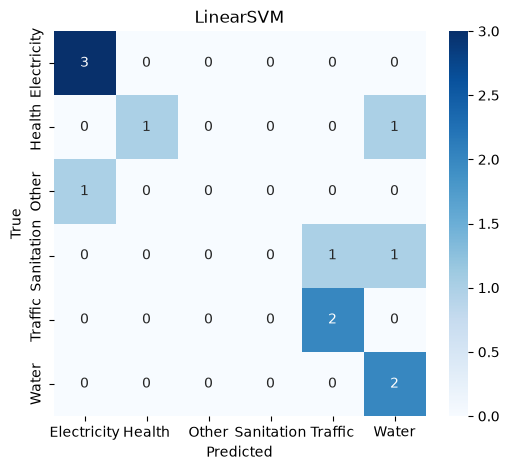

,model,accuracy,macro_P,macro_R,macro_F1,weighted_P,weighted_R,weighted_F1
0,NaiveBayes,0.417,0.156,0.333,0.208,0.206,0.417,0.271
1,LinearSVM,0.667,0.486,0.583,0.498,0.549,0.667,0.570


In [10]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

preds, rows = {}, []
for name, m in models.items():
    p = m.predict(X_test)
    preds[name] = p
    row = {"model": name, "accuracy": round(accuracy_score(y_test, p), 3)}
    for avg in ["macro", "weighted"]:
        P, R, F, _ = precision_recall_fscore_support(y_test, p, average=avg, zero_division=0)
        row[f"{avg}_P"], row[f"{avg}_R"], row[f"{avg}_F1"] = round(P, 3), round(R, 3), round(F, 3)
    rows.append(row)

    cm = confusion_matrix(y_test, p, labels=labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.title(name); plt.ylabel("True"); plt.xlabel("Predicted")
    plt.savefig(f"results/cm_{name}.png", dpi=150, bbox_inches="tight")   # report ke liye
    plt.show()

metrics = pd.DataFrame(rows)
save_table(metrics, "B2_metrics")
metrics

In [11]:
save_note("B1_split", "70/30 stratified, random_state=42, train=28, test=12")
save_note("B2_NB_accuracy", 0.417)
save_note("B2_SVM_accuracy", 0.667)
save_note("B2_NB_macro_F1", 0.208)
save_note("B2_SVM_macro_F1", 0.498)

In [12]:
from collections import Counter

yt = y_test.to_numpy()   # plain array, taake position se compare ho
for name, p in preds.items():
    print("=====", name)
    wrong = p != yt
    # (true -> predicted) jodiyon ki ginti: sab se zyada confusion kahan hai
    print(Counter(zip(yt[wrong], p[wrong])).most_common())
    for pos in np.where(wrong)[0]:
        idx = y_test.index[pos]
        print(df.loc[idx, "ticket_id"], "| true:", yt[pos], "| pred:", p[pos])
        print("    ", df.loc[idx, "complaint_text"])

===== NaiveBayes
[(('Health', np.str_('Water')), 2), (('Traffic', np.str_('Electricity')), 1), (('Traffic', np.str_('Water')), 1), (('Other', np.str_('Electricity')), 1), (('Sanitation', np.str_('Water')), 1), (('Sanitation', np.str_('Traffic')), 1)]
IMH-027 | true: Traffic | pred: Electricity
     Traffic police blocked the I-8 underpass during peak hours.
IMH-023 | true: Traffic | pred: Water
     Double parking by diplomatic cars near the embassy in Diplomatic Enclave. Local vans cannot pass.
IMH-040 | true: Other | pred: Electricity
     Can IMH share the WhatsApp number of the Director Sanitation? Our union council chairman Mr Bilal wants a meeting.
IMH-020 | true: Health | pred: Water
     Lady doctor at BHU Koral was on leave and no replacement came. Women from nearby villages waited till noon.
IMH-038 | true: Health | pred: Water
     Ambulance from 1122 took 40 minutes to reach Bhara Kahu. The operator said no vehicle was free.
IMH-025 | true: Sanitation | pred: Water
     Ope

In [13]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold

# 12 test tickets mein disagreement shayad na mile, isliye poore 40 tickets pe 4-fold
# (4-fold isliye ke "Other" class mein total sirf 4 tickets hain)
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
cvp = {n: cross_val_predict(m, df["clean"], df["department"], cv=cv)
       for n, m in models.items()}

truth = df["department"].to_numpy()
print("CV accuracy NB :", round((cvp["NaiveBayes"] == truth).mean(), 3))
print("CV accuracy SVM:", round((cvp["LinearSVM"] == truth).mean(), 3))

mask = cvp["NaiveBayes"] != cvp["LinearSVM"]      # jahan dono ne alag jawab diya
dis = df[mask].copy()
dis["NB"] = cvp["NaiveBayes"][mask]
dis["SVM"] = cvp["LinearSVM"][mask]
dis = dis[["ticket_id", "department", "NB", "SVM", "complaint_text"]]
save_table(dis, "B3_disagreements")
print("disagreements:", len(dis))
dis

CV accuracy NB : 0.375
CV accuracy SVM: 0.475
disagreements: 14


,ticket_id,department,NB,SVM,complaint_text
4,IMH-005,Traffic,Electricity,Water,Illegal parking in front of Centaurus Mall is ...
5,IMH-006,Health,Electricity,Sanitation,PIMS emergency waiting time was more than 4 ho...
8,IMH-009,Sanitation,Electricity,Traffic,Sewerage overflow outside Faisal Mosque parkin...
11,IMH-012,Traffic,Electricity,Traffic,Signal at Faisal Avenue and Jinnah Avenue is n...
12,IMH-013,Health,Electricity,Water,Polyclinic hospital pharmacy had no medicine f...
16,IMH-017,Traffic,Electricity,Health,Road blockage on Kashmir Highway due to a brok...
17,IMH-018,Sanitation,Electricity,Health,Someone dumped medical waste behind PIMS hostel.
21,IMH-022,Water,Electricity,Traffic,No pressure in overhead tank of Street 22 G-13...
25,IMH-026,Health,Electricity,Water,Dengue spray was not done in Ali Pur this mont...
26,IMH-027,Traffic,Electricity,Traffic,Traffic police blocked the I-8 underpass durin...


In [14]:
from collections import Counter

print("NB predictions :", Counter(cvp["NaiveBayes"]))
print("SVM predictions:", Counter(cvp["LinearSVM"]))
print("True labels    :", Counter(df["department"]))

# Diagnostic (final model nahi): alpha chhota karke dekho, smoothing ka asar
for a in [1.0, 0.3, 0.1, 0.01]:
    m = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
                  ("clf", MultinomialNB(alpha=a))])
    p = cross_val_predict(m, df["clean"], df["department"], cv=cv)
    print(f"alpha={a}: CV acc={round((p == truth).mean(), 3)}, Electricity predicted {sum(p == 'Electricity')} times")

NB predictions : Counter({np.str_('Electricity'): 28, np.str_('Water'): 8, np.str_('Sanitation'): 4})
SVM predictions: Counter({'Electricity': 14, 'Water': 12, 'Sanitation': 7, 'Traffic': 4, 'Health': 3})
True labels    : Counter({'Electricity': 9, 'Water': 8, 'Sanitation': 7, 'Traffic': 6, 'Health': 6, 'Other': 4})
alpha=1.0: CV acc=0.375, Electricity predicted 28 times
alpha=0.3: CV acc=0.375, Electricity predicted 16 times
alpha=0.1: CV acc=0.425, Electricity predicted 11 times
alpha=0.01: CV acc=0.4, Electricity predicted 7 times


In [15]:
save_note("B3_NB_CV_pred_counts", {"Electricity": 28, "Water": 8, "Sanitation": 4})
save_note("B3_SVM_CV_pred_counts", {"Electricity": 14, "Water": 12, "Sanitation": 7, "Traffic": 4, "Health": 3})
save_note("B3_NB_alpha_diagnostic_CV_acc", {"1.0": 0.375, "0.3": 0.375, "0.1": 0.425, "0.01": 0.4})

In [16]:
from sklearn.metrics import classification_report

for n in cvp:
    print("=====", n, "(4-fold CV, 40 tickets)")
    # har class ka precision/recall/F1 aur aakhir mein overall accuracy
    print(classification_report(truth, cvp[n], zero_division=0))

===== NaiveBayes (4-fold CV, 40 tickets)
              precision    recall  f1-score   support

 Electricity       0.32      1.00      0.49         9
      Health       0.00      0.00      0.00         6
       Other       0.00      0.00      0.00         4
  Sanitation       0.00      0.00      0.00         7
     Traffic       0.00      0.00      0.00         6
       Water       0.75      0.75      0.75         8

    accuracy                           0.38        40
   macro avg       0.18      0.29      0.21        40
weighted avg       0.22      0.38      0.26        40

===== LinearSVM (4-fold CV, 40 tickets)
              precision    recall  f1-score   support

 Electricity       0.64      1.00      0.78         9
      Health       0.33      0.17      0.22         6
       Other       0.00      0.00      0.00         4
  Sanitation       0.14      0.14      0.14         7
     Traffic       0.50      0.33      0.40         6
       Water       0.50      0.75      0.60        

In [17]:
save_note("B3_NB_CV_accuracy", 0.375)
save_note("B3_SVM_CV_accuracy", 0.475)
save_note("B3_SVM_CV_per_class_F1", {"Electricity": 0.78, "Health": 0.22, "Other": 0.0,
                                      "Sanitation": 0.14, "Traffic": 0.40, "Water": 0.60})
save_note("B3_SVM_CV_macro_F1", 0.36)
save_note("B3_NB_CV_macro_F1", 0.21)

In [18]:
from collections import Counter

yt = y_test.to_numpy()   # plain array, taake position se compare ho
for name, p in preds.items():
    print("=====", name)
    wrong = p != yt
    # (true -> predicted) jodiyon ki ginti: sab se zyada confusion kahan hai
    print(Counter(zip(yt[wrong], p[wrong])).most_common())
    for pos in np.where(wrong)[0]:
        idx = y_test.index[pos]
        print(df.loc[idx, "ticket_id"], "| true:", yt[pos], "| pred:", p[pos])
        print("    ", df.loc[idx, "complaint_text"])

===== NaiveBayes
[(('Health', np.str_('Water')), 2), (('Traffic', np.str_('Electricity')), 1), (('Traffic', np.str_('Water')), 1), (('Other', np.str_('Electricity')), 1), (('Sanitation', np.str_('Water')), 1), (('Sanitation', np.str_('Traffic')), 1)]
IMH-027 | true: Traffic | pred: Electricity
     Traffic police blocked the I-8 underpass during peak hours.
IMH-023 | true: Traffic | pred: Water
     Double parking by diplomatic cars near the embassy in Diplomatic Enclave. Local vans cannot pass.
IMH-040 | true: Other | pred: Electricity
     Can IMH share the WhatsApp number of the Director Sanitation? Our union council chairman Mr Bilal wants a meeting.
IMH-020 | true: Health | pred: Water
     Lady doctor at BHU Koral was on leave and no replacement came. Women from nearby villages waited till noon.
IMH-038 | true: Health | pred: Water
     Ambulance from 1122 took 40 minutes to reach Bhara Kahu. The operator said no vehicle was free.
IMH-025 | true: Sanitation | pred: Water
     Ope

In [19]:
from collections import Counter

p = cvp["LinearSVM"]
wrong = p != truth
# (true -> predicted) ginti, 40 tickets par
print(Counter(zip(truth[wrong], p[wrong])).most_common())

# Unordered pairs (A<->B), taake dono taraf ka confusion jama ho
pairs = Counter(tuple(sorted(x)) for x in zip(truth[wrong], p[wrong]))
print(pairs.most_common())

[(('Sanitation', 'Water'), 3), (('Health', 'Sanitation'), 3), (('Other', 'Electricity'), 3), (('Health', 'Water'), 2), (('Traffic', 'Sanitation'), 2), (('Traffic', 'Water'), 1), (('Sanitation', 'Traffic'), 1), (('Sanitation', 'Electricity'), 1), (('Traffic', 'Health'), 1), (('Sanitation', 'Health'), 1), (('Other', 'Sanitation'), 1), (('Water', 'Traffic'), 1), (('Water', 'Electricity'), 1)]
[(('Health', 'Sanitation'), 4), (('Sanitation', 'Water'), 3), (('Sanitation', 'Traffic'), 3), (('Electricity', 'Other'), 3), (('Traffic', 'Water'), 2), (('Health', 'Water'), 2), (('Electricity', 'Sanitation'), 1), (('Health', 'Traffic'), 1), (('Other', 'Sanitation'), 1), (('Electricity', 'Water'), 1)]


In [20]:
svm = models["LinearSVM"]
vec, clf = svm.named_steps["tfidf"], svm.named_steps["clf"]
names = vec.get_feature_names_out()

# Har class ke sab se mazboot features (SVM ke weights)
for i, cls in enumerate(clf.classes_):
    top = clf.coef_[i].argsort()[::-1][:8]
    print(cls, "->", [names[j] for j in top])

# IMH-009 ke kaunse words model ki vocabulary mein hain
t = df.loc[df.ticket_id == "IMH-009", "clean"].iloc[0]
print("\nIMH-009 words jo model ne dekhe:", [names[j] for j in vec.transform([t]).nonzero()[1]])

Electricity -> ['iesco', 'g9', 'meter', 'g9 submitted', 'of g9', 'submitted complaint', 'about the', 'the residents']
Health -> ['patient', 'was', 'hospital', 'dengue', 'had', 'ms sara', 'bibi were', 'fgsh']
Other -> ['to', 'me how', 'to apply', 'blue area', 'me', 'blue', 'in blue', 'new']
Sanitation -> ['days', 'medical', 'waste behind', 'medical waste', 'dumped medical', 'behind', 'behind pims', 'hostel']
Traffic -> ['avenue', 'parking', 'are', 'on', 'are parking', 'parking on', 'f7', 'crossing in']
Water -> ['water', 'street', 'cda', 'tanker', 'since', 'at', 'near', 'tanker did']

IMH-009 words jo model ne dekhe: ['are', 'faisal', 'from', 'parking', 'school']


In [21]:
p = cvp["LinearSVM"]
mask = ((truth == "Health") & (p == "Sanitation")) | ((truth == "Sanitation") & (p == "Health"))
out = df[mask].copy()
out["pred"] = p[mask]
for _, r in out.iterrows():
    print(r.ticket_id, "| true:", r.department, "| pred:", r.pred)
    print("    ", r.complaint_text)

IMH-006 | true: Health | pred: Sanitation
     PIMS emergency waiting time was more than 4 hours yesterday. A patient from Rawalpindi collapsed in the corridor.
IMH-018 | true: Sanitation | pred: Health
     Someone dumped medical waste behind PIMS hostel.
IMH-020 | true: Health | pred: Sanitation
     Lady doctor at BHU Koral was on leave and no replacement came. Women from nearby villages waited till noon.
IMH-032 | true: Health | pred: Sanitation
     FGSH hospital discharge papers of Ms Sara Bibi were mixed with another patient.


In [22]:
save_note("B2_most_confused_pair_CV", "Health<->Sanitation, 4 errors of 21")
save_note("B2_Sanitation_involved_errors_CV", "12 of 21")
save_note("B2_SVM_CV_pair_counts", {"Health-Sanitation": 4, "Sanitation-Water": 3, "Sanitation-Traffic": 3,
                                    "Electricity-Other": 3, "Health-Water": 2, "Traffic-Water": 2})

In [23]:
svm = models["LinearSVM"]
vec, clf = svm.named_steps["tfidf"], svm.named_steps["clf"]
names = vec.get_feature_names_out()

# Har class ke 8 sab se mazboot features (ye model 28 train tickets pe seekha hai, CV pe nahi)
for i, cls in enumerate(clf.classes_):
    top = clf.coef_[i].argsort()[::-1][:8]
    print(cls, "->", [names[j] for j in top])

# In 4 tickets ke kitne words model ki vocabulary mein the
for tid in ["IMH-006", "IMH-018", "IMH-020", "IMH-032"]:
    t = df.loc[df.ticket_id == tid, "clean"].iloc[0]
    seen = [names[j] for j in vec.transform([t]).nonzero()[1]]
    print("\n", tid, "-> words seen:", len(seen), "of", len(t.split()), "raw words")
    print("   ", seen)

Electricity -> ['iesco', 'g9', 'meter', 'g9 submitted', 'of g9', 'submitted complaint', 'about the', 'the residents']
Health -> ['patient', 'was', 'hospital', 'dengue', 'had', 'ms sara', 'bibi were', 'fgsh']
Other -> ['to', 'me how', 'to apply', 'blue area', 'me', 'blue', 'in blue', 'new']
Sanitation -> ['days', 'medical', 'waste behind', 'medical waste', 'dumped medical', 'behind', 'behind pims', 'hostel']
Traffic -> ['avenue', 'parking', 'are', 'on', 'are parking', 'parking on', 'f7', 'crossing in']
Water -> ['water', 'street', 'cda', 'tanker', 'since', 'at', 'near', 'tanker did']

 IMH-006 -> words seen: 31 of 18 raw words
    ['collapsed', 'collapsed in', 'corridor', 'emergency', 'emergency waiting', 'from', 'from rawalpindi', 'hours', 'hours yesterday', 'in', 'in the', 'more', 'more than', 'patient', 'patient from', 'pims', 'pims emergency', 'rawalpindi', 'rawalpindi collapsed', 'than', 'than hours', 'the', 'the corridor', 'time', 'time was', 'waiting', 'waiting time', 'was', 'was

In [24]:
save_note("B2_quoted_error_ticket", "IMH-018 true Sanitation pred Health (SVM)")
save_note("B2_health_sanitation_tickets", ["IMH-006", "IMH-018", "IMH-020", "IMH-032"])

In [25]:
import re
from sklearn.base import clone

# (1) Unigram OOV check, sirf test-set ke tickets par valid
vocab = set(vec.get_feature_names_out())
test_ids = set(df.loc[X_test.index, "ticket_id"])
for tid in ["IMH-009", "IMH-020", "IMH-025", "IMH-040"]:
    t = df.loc[df.ticket_id == tid, "clean"].iloc[0]
    toks = re.findall(r"\b\w\w+\b", t)       # sklearn ka default tokenizer jaisa
    unk = [w for w in toks if w not in vocab]
    print(tid, "in_test:", tid in test_ids, "| unseen:", len(unk), "of", len(toks), unk)

# (2) IMH-018 ko train se nikal ke Health vs Sanitation ka hisaab
i = df.index[df.ticket_id == "IMH-018"][0]
rest = df.drop(index=i)
m = clone(models["LinearSVM"]).fit(rest["clean"], rest["department"])
txt = df.loc[i, "clean"]
print("\nscores:", dict(zip(m.classes_, m.decision_function([txt])[0].round(3))))
v, c = m.named_steps["tfidf"], m.named_steps["clf"]
x = v.transform([txt]); names = v.get_feature_names_out()
for k in x.nonzero()[1]:
    print(names[k], {cls: round(float(x[0, k] * c.coef_[ci, k]), 3)
                     for ci, cls in enumerate(c.classes_) if cls in ("Health", "Sanitation")})

IMH-009 in_test: True | unseen: 8 of 13 ['sewerage', 'overflow', 'outside', 'mosque', 'children', 'nearby', 'falling', 'sick']
IMH-020 in_test: True | unseen: 11 of 19 ['lady', 'doctor', 'bhu', 'koral', 'leave', 'replacement', 'came', 'nearby', 'villages', 'waited', 'noon']
IMH-025 in_test: True | unseen: 8 of 13 ['open', 'manhole', 'service', 'south', 'karachi', 'company', 'motorbikes', 'fell']
IMH-040 in_test: True | unseen: 12 of 18 ['can', 'imh', 'share', 'whatsapp', 'number', 'director', 'union', 'council', 'chairman', 'bilal', 'wants', 'meeting']

scores: {'Electricity': np.float64(-0.573), 'Health': np.float64(-0.434), 'Other': np.float64(-0.767), 'Sanitation': np.float64(-0.709), 'Traffic': np.float64(-0.696), 'Water': np.float64(-0.633)}
pims {'Health': 0.205, 'Sanitation': -0.044}


In [26]:
save_note("B_IMH009_unseen_words", "sewerage, overflow, mosque, sick etc OOV; known words parking/are/faisal are Traffic top features")
save_note("B_IMH020_known_words", "only 8 function words known; doctor/lady/bhu/koral OOV")
save_note("B_note", "IMH-006/018/032 are in train split; Cell 18 top features memorize them")
save_note("B3_spurious_features", "stopwords (was, had, to, are, on, at, since) in class top features")

In [27]:
import spacy
nlp = spacy.load("en_core_web_sm")
print("spaCy", spacy.__version__)

# NER ke liye RAW text use hota hai, clean nahi: spaCy capital letters dekh kar
# naam pehchanta hai ("Faisal" vs "faisal"), lowercase karne se wo kamzor ho jata hai
df["spacy_ents"] = df["complaint_text"].apply(
    lambda t: [(e.text, e.label_) for e in nlp(t).ents])

# gold_entities ko list of (text, type) mein badlo: "G-9|LOC; IESCO|ORG"
def parse_gold(s):
    out = []
    for part in str(s).split(";"):
        if "|" in part:
            txt, typ = part.rsplit("|", 1)
            out.append((txt.strip(), typ.strip()))
    return out
df["gold"] = df["gold_entities"].apply(parse_gold)

for tid in ["IMH-001", "IMH-004", "IMH-018", "IMH-029"]:
    r = df[df.ticket_id == tid].iloc[0]
    print(tid, "|", r.complaint_text)
    print("   gold :", r.gold)
    print("   spaCy:", r.spacy_ents, "\n")

spaCy 3.8.16
IMH-001 | Bijli nahi aa rahi Sector G-9 Islamabad mein last 8 hours se. IESCO helpline does not pick the call.
   gold : [('Sector G-9', 'LOC'), ('Islamabad', 'LOC'), ('IESCO', 'ORG')]
   spaCy: [('Bijli nahi aa rahi', 'PERSON'), ('G-9 Islamabad', 'LOC'), ('last 8 hours', 'TIME'), ('helpline', 'GPE')] 

IMH-004 | The residents of G-9 submitted a complaint about the transformer.
   gold : [('G-9', 'LOC')]
   spaCy: [('G-9', 'ORG')] 

IMH-018 | Someone dumped medical waste behind PIMS hostel.
   gold : [('PIMS', 'ORG')]
   spaCy: [] 

IMH-029 | New connection requested 3 months ago by Mr Ahmed Khan of House 14 Street 9 G-11. IESCO file is lost.
   gold : [('Ahmed Khan', 'PER'), ('House 14', 'LOC'), ('Street 9', 'LOC'), ('G-11', 'LOC'), ('IESCO', 'ORG')]
   spaCy: [('3 months ago', 'DATE'), ('Ahmed Khan', 'PERSON'), ('House', 'ORG'), ('14 Street 9 G-11', 'PRODUCT')] 



In [28]:
import re

TYPE_MAP = {"PERSON": "PER", "GPE": "LOC", "LOC": "LOC", "FAC": "LOC", "ORG": "ORG"}

def spacy_spans(text):
    # (start, end, text, type): sirf PER/LOC/ORG, DATE/TIME/PRODUCT chhor do
    return [(e.start_char, e.end_char, e.text, TYPE_MAP[e.label_])
            for e in nlp(text).ents if e.label_ in TYPE_MAP]

# Rule layer: Islamabad ke known idaare aur sector/street codes
ORG_PATTERNS = [r"\b(?:IESCO|CDA|PIMS|FGSH|WASA)\b",
                r"\bBHU(?:\s+[A-Z][a-z]+)?\b"]            # BHU + jagah ka naam
LOC_PATTERNS = [r"(?:Sector\s+)?\b[A-Z]-\d{1,2}(?:/\d)?(?:\s+Markaz)?\b",   # Sector G-9, G-10/3, I-8 Markaz
                r"\b(?:Street|House)\s+\d+\b"]                              # Street 7, House 14

def rule_spans(text):
    out = []
    for pats, ty in [(ORG_PATTERNS, "ORG"), (LOC_PATTERNS, "LOC")]:
        for pat in pats:
            out += [(m.start(), m.end(), m.group(), ty) for m in re.finditer(pat, text)]
    return out

def overlaps(a, b):
    return a[0] < b[1] and b[0] < a[1]

def hybrid(text):
    rules = rule_spans(text)
    # jahan rule aur spaCy takrayen, rule jeetta hai (spaCy in codes par bharose ke qabil nahi)
    kept = [s for s in spacy_spans(text) if not any(overlaps(s, r) for r in rules)]
    return sorted(kept + rules)

df["ner_spacy"] = df["complaint_text"].apply(spacy_spans)
df["ner_hybrid"] = df["complaint_text"].apply(hybrid)

# C1: 3 tickets par before/after
for tid in ["IMH-001", "IMH-018", "IMH-029"]:
    r = df[df.ticket_id == tid].iloc[0]
    print(tid, "|", r.complaint_text)
    print("  gold  :", r.gold)
    print("  BEFORE:", [(s[2], s[3]) for s in r.ner_spacy])
    print("  AFTER :", [(s[2], s[3]) for s in r.ner_hybrid], "\n")

IMH-001 | Bijli nahi aa rahi Sector G-9 Islamabad mein last 8 hours se. IESCO helpline does not pick the call.
  gold  : [('Sector G-9', 'LOC'), ('Islamabad', 'LOC'), ('IESCO', 'ORG')]
  BEFORE: [('Bijli nahi aa rahi', 'PER'), ('G-9 Islamabad', 'LOC'), ('helpline', 'LOC')]
  AFTER : [('Bijli nahi aa rahi', 'PER'), ('Sector G-9', 'LOC'), ('IESCO', 'ORG'), ('helpline', 'LOC')] 

IMH-018 | Someone dumped medical waste behind PIMS hostel.
  gold  : [('PIMS', 'ORG')]
  BEFORE: []
  AFTER : [('PIMS', 'ORG')] 

IMH-029 | New connection requested 3 months ago by Mr Ahmed Khan of House 14 Street 9 G-11. IESCO file is lost.
  gold  : [('Ahmed Khan', 'PER'), ('House 14', 'LOC'), ('Street 9', 'LOC'), ('G-11', 'LOC'), ('IESCO', 'ORG')]
  BEFORE: [('Ahmed Khan', 'PER'), ('House', 'ORG')]
  AFTER : [('Ahmed Khan', 'PER'), ('House 14', 'LOC'), ('Street 9', 'LOC'), ('G-11', 'LOC'), ('IESCO', 'ORG')] 



In [29]:
from collections import defaultdict

def evaluate(col):
    tp, fp, fn = defaultdict(int), defaultdict(int), defaultdict(int)
    for _, r in df.iterrows():
        g = {(t.lower(), y) for t, y in r.gold if y in ("PER", "LOC", "ORG")}
        p = {(s[2].lower(), s[3]) for s in r[col]}
        for _, y in p & g: tp[y] += 1       # sahi (text aur type dono match)
        for _, y in p - g: fp[y] += 1       # model ne diya, gold mein nahi
        for _, y in g - p: fn[y] += 1       # gold mein tha, model ne miss kiya
    rows = []
    for ty in ["PER", "LOC", "ORG", "ALL"]:
        a = sum(tp.values()) if ty == "ALL" else tp[ty]
        b = sum(fp.values()) if ty == "ALL" else fp[ty]
        c = sum(fn.values()) if ty == "ALL" else fn[ty]
        P = a / (a + b) if a + b else 0
        R = a / (a + c) if a + c else 0
        F = 2 * P * R / (P + R) if P + R else 0
        rows.append({"system": col, "type": ty, "TP": a, "FP": b, "FN": c,
                     "P": round(P, 3), "R": round(R, 3), "F1": round(F, 3)})
    return pd.DataFrame(rows)

ner_res = pd.concat([evaluate("ner_spacy"), evaluate("ner_hybrid")], ignore_index=True)
save_table(ner_res, "C2_ner_results")
ner_res

,system,type,TP,FP,FN,P,R,F1
0,ner_spacy,PER,2,14,3,0.125,0.400,0.190
1,ner_spacy,LOC,13,5,34,0.722,0.277,0.400
2,ner_spacy,ORG,9,11,12,0.450,0.429,0.439
3,ner_spacy,ALL,24,30,49,0.444,0.329,0.378
4,ner_hybrid,PER,2,13,3,0.133,0.400,0.200
5,ner_hybrid,LOC,34,4,13,0.895,0.723,0.800
6,ner_hybrid,ORG,18,7,3,0.720,0.857,0.783
7,ner_hybrid,ALL,54,24,19,0.692,0.740,0.715


In [30]:
save_note("C_baseline_findings", "spaCy: Bijli nahi aa rahi->PERSON, G-9->ORG, PIMS/IESCO missed, 14 Street 9 G-11->PRODUCT")
save_note("C_leakage_note", "rules written after viewing the same 40 tickets; C2 scores are optimistic, not held-out")

In [31]:
import re

# spaCy ke labels ko assignment ke labels mein map karo (DATE/TIME/PRODUCT ignore)
TYPE_MAP = {"PERSON": "PER", "GPE": "LOC", "LOC": "LOC", "FAC": "LOC", "ORG": "ORG"}

def spacy_spans(text):
    return [(e.start_char, e.end_char, e.text, TYPE_MAP[e.label_])
            for e in nlp(text).ents if e.label_ in TYPE_MAP]

# Rules: Islamabad ke idaare aur sector/street codes (domain knowledge se, gold se copy nahi)
ORG_PATTERNS = [r"\b(?:IESCO|CDA|PIMS|FGSH|WASA)\b",
                r"\bBHU(?:\s+[A-Z][a-z]+)?\b"]
LOC_PATTERNS = [r"(?:Sector\s+)?\b[A-Z]-\d{1,2}(?:/\d)?(?:\s+Markaz)?\b",
                r"\b(?:Street|House)\s+\d+\b"]

def rule_spans(text):
    out = []
    for pats, ty in [(ORG_PATTERNS, "ORG"), (LOC_PATTERNS, "LOC")]:
        for pat in pats:
            out += [(m.start(), m.end(), m.group(), ty) for m in re.finditer(pat, text)]
    return out

def overlaps(a, b):
    return a[0] < b[1] and b[0] < a[1]

def hybrid(text):
    rules = rule_spans(text)
    kept = [s for s in spacy_spans(text) if not any(overlaps(s, r) for r in rules)]
    return sorted(kept + rules)   # overlap par rule jeetta hai

df["ner_spacy"] = df["complaint_text"].apply(spacy_spans)
df["ner_hybrid"] = df["complaint_text"].apply(hybrid)

for tid in ["IMH-001", "IMH-018", "IMH-029"]:
    r = df[df.ticket_id == tid].iloc[0]
    print(tid, "|", r.complaint_text)
    print("  gold  :", r.gold)
    print("  BEFORE:", [(s[2], s[3]) for s in r.ner_spacy])
    print("  AFTER :", [(s[2], s[3]) for s in r.ner_hybrid], "\n")

IMH-001 | Bijli nahi aa rahi Sector G-9 Islamabad mein last 8 hours se. IESCO helpline does not pick the call.
  gold  : [('Sector G-9', 'LOC'), ('Islamabad', 'LOC'), ('IESCO', 'ORG')]
  BEFORE: [('Bijli nahi aa rahi', 'PER'), ('G-9 Islamabad', 'LOC'), ('helpline', 'LOC')]
  AFTER : [('Bijli nahi aa rahi', 'PER'), ('Sector G-9', 'LOC'), ('IESCO', 'ORG'), ('helpline', 'LOC')] 

IMH-018 | Someone dumped medical waste behind PIMS hostel.
  gold  : [('PIMS', 'ORG')]
  BEFORE: []
  AFTER : [('PIMS', 'ORG')] 

IMH-029 | New connection requested 3 months ago by Mr Ahmed Khan of House 14 Street 9 G-11. IESCO file is lost.
  gold  : [('Ahmed Khan', 'PER'), ('House 14', 'LOC'), ('Street 9', 'LOC'), ('G-11', 'LOC'), ('IESCO', 'ORG')]
  BEFORE: [('Ahmed Khan', 'PER'), ('House', 'ORG')]
  AFTER : [('Ahmed Khan', 'PER'), ('House 14', 'LOC'), ('Street 9', 'LOC'), ('G-11', 'LOC'), ('IESCO', 'ORG')] 



In [32]:
from collections import defaultdict

def evaluate(col):
    tp, fp, fn = defaultdict(int), defaultdict(int), defaultdict(int)
    for _, r in df.iterrows():
        g = {(t.lower(), y) for t, y in r.gold if y in ("PER", "LOC", "ORG")}
        p = {(s[2].lower(), s[3]) for s in r[col]}
        for _, y in p & g: tp[y] += 1   # text aur type dono sahi
        for _, y in p - g: fp[y] += 1   # model ne diya, gold mein nahi
        for _, y in g - p: fn[y] += 1   # gold mein tha, model ne miss kiya
    rows = []
    for ty in ["PER", "LOC", "ORG", "ALL"]:
        a = sum(tp.values()) if ty == "ALL" else tp[ty]
        b = sum(fp.values()) if ty == "ALL" else fp[ty]
        c = sum(fn.values()) if ty == "ALL" else fn[ty]
        P = a / (a + b) if a + b else 0
        R = a / (a + c) if a + c else 0
        F = 2 * P * R / (P + R) if P + R else 0
        rows.append({"system": col, "type": ty, "TP": a, "FP": b, "FN": c,
                     "P": round(P, 3), "R": round(R, 3), "F1": round(F, 3)})
    return pd.DataFrame(rows)

ner_res = pd.concat([evaluate("ner_spacy"), evaluate("ner_hybrid")], ignore_index=True)
save_table(ner_res, "C2_ner_results")
ner_res

,system,type,TP,FP,FN,P,R,F1
0,ner_spacy,PER,2,14,3,0.125,0.400,0.190
1,ner_spacy,LOC,13,5,34,0.722,0.277,0.400
2,ner_spacy,ORG,9,11,12,0.450,0.429,0.439
3,ner_spacy,ALL,24,30,49,0.444,0.329,0.378
4,ner_hybrid,PER,2,13,3,0.133,0.400,0.200
5,ner_hybrid,LOC,34,4,13,0.895,0.723,0.800
6,ner_hybrid,ORG,18,7,3,0.720,0.857,0.783
7,ner_hybrid,ALL,54,24,19,0.692,0.740,0.715


In [33]:
for _, r in df.iterrows():
    g = {(t.lower(), y) for t, y in r.gold if y in ("PER", "LOC", "ORG")}
    p = {(s[2].lower(), s[3]) for s in r.ner_hybrid}
    if g != p:
        print(r.ticket_id, "|", r.complaint_text)
        print("   missed (FN):", sorted(g - p))
        print("   wrong  (FP):", sorted(p - g))

IMH-001 | Bijli nahi aa rahi Sector G-9 Islamabad mein last 8 hours se. IESCO helpline does not pick the call.
   missed (FN): [('islamabad', 'LOC')]
   wrong  (FP): [('bijli nahi aa rahi', 'PER'), ('helpline', 'LOC')]
IMH-006 | PIMS emergency waiting time was more than 4 hours yesterday. A patient from Rawalpindi collapsed in the corridor.
   missed (FN): [('rawalpindi', 'LOC')]
   wrong  (FP): [('rawalpindi', 'PER')]
IMH-007 | Pipe burst on Khayaban-e-Iqbal near Melody Food Park. Water is wasting since 6am.
   missed (FN): [('khayaban-e-iqbal', 'LOC')]
   wrong  (FP): []
IMH-008 | Meter reader from IESCO overcharged our house in G-10/3. Bill is 45000 which is impossible.
   missed (FN): []
   wrong  (FP): [('bill', 'PER'), ('meter', 'PER')]
IMH-009 | Sewerage overflow outside Faisal Mosque parking. Children from nearby school are falling sick.
   missed (FN): [('faisal mosque', 'LOC')]
   wrong  (FP): [('faisal mosque', 'ORG')]
IMH-012 | Signal at Faisal Avenue and Jinnah Avenue is n

In [34]:
save_note("C2_spacy_ALL_PRF1", [0.444, 0.329, 0.378])
save_note("C2_hybrid_ALL_PRF1", [0.692, 0.740, 0.715])
save_note("C2_hybrid_LOC_F1", 0.800)
save_note("C2_hybrid_ORG_F1", 0.783)
save_note("C2_hybrid_PER", "P=0.133 R=0.4 F1=0.2 (only 5 gold PER)")
save_note("C2_PER_FP_breakdown", "13 FP: 6 place names, 3 common nouns (bill/meter/nullah), 2 Roman Urdu, 2 honorific boundary")
save_note("C2_errors", "Islamabad lost in IMH-001 due to overlap rule; gold inconsistent E-11 vs Sector G-9; rules written after seeing data (optimistic)")

In [35]:
D_IDS = ["IMH-004", "IMH-011", "IMH-018", "IMH-027", "IMH-033"]

def ascii_tree(tok, indent=""):
    print(f"{indent}{tok.text}  [{tok.dep_}]")
    for ch in tok.children:            # children sentence ke order mein aate hain
        ascii_tree(ch, indent + "    ")

for tid in D_IDS:
    text = df.loc[df.ticket_id == tid, "complaint_text"].iloc[0]
    doc = nlp(text)
    print("=" * 60, "\n", tid, "|", text)
    for t in doc:   # UAS/LAS ke liye: har token ka index, label, head ka index
        print(f"{t.i:>2} {t.text:<14} dep={t.dep_:<8} head={t.head.i}({t.head.text}) pos={t.pos_}")
    print("\nTree:")
    ascii_tree(next(doc.sents).root)
    print("Noun chunks:", [c.text for c in doc.noun_chunks])

 IMH-004 | The residents of G-9 submitted a complaint about the transformer.
 0 The            dep=det      head=1(residents) pos=DET
 1 residents      dep=nsubj    head=4(submitted) pos=NOUN
 2 of             dep=prep     head=1(residents) pos=ADP
 3 G-9            dep=pobj     head=2(of) pos=PROPN
 4 submitted      dep=ROOT     head=4(submitted) pos=VERB
 5 a              dep=det      head=6(complaint) pos=DET
 6 complaint      dep=dobj     head=4(submitted) pos=NOUN
 7 about          dep=prep     head=4(submitted) pos=ADP
 8 the            dep=det      head=9(transformer) pos=DET
 9 transformer    dep=pobj     head=7(about) pos=NOUN
10 .              dep=punct    head=4(submitted) pos=PUNCT

Tree:
submitted  [ROOT]
    residents  [nsubj]
        The  [det]
        of  [prep]
            G-9  [pobj]
    complaint  [dobj]
        a  [det]
    about  [prep]
        transformer  [pobj]
            the  [det]
    .  [punct]
Noun chunks: ['The residents', 'G-9', 'a complaint', 'the transf

In [36]:
# 4-fold CV mein SVM ke decision scores (har class ka margin)
scores = cross_val_predict(models["LinearSVM"], df["clean"], df["department"],
                           cv=cv, method="decision_function")
classes = np.array(sorted(df["department"].unique()))   # columns isi order mein hain
top = scores.max(axis=1)                                 # sab se bada score = model ka "bharosa"
pred = classes[scores.argmax(axis=1)]

# NOTE: LinearSVC ke scores probability nahi hote, to "0.75" seedha lagana ghalat hoga.
# Isliye thresholds ko scores ke quantiles se lete hain.
rows = []
for q in [0.0, 0.2, 0.4, 0.6, 0.8]:
    th = np.quantile(top, q)
    auto = top >= th                       # auto-route, baaki human queue mein
    rows.append({"threshold": round(float(th), 3),
                 "auto_routed": int(auto.sum()),
                 "coverage": round(float(auto.mean()), 3),
                 "accuracy_on_auto": round(float((pred[auto] == truth[auto]).mean()), 3),
                 "wrong_auto": int((pred[auto] != truth[auto]).sum()),
                 "Health_to_Sanitation": int(((truth[auto] == "Health") & (pred[auto] == "Sanitation")).sum())})
thr_df = pd.DataFrame(rows)
save_table(thr_df, "E2_threshold_table")
thr_df

,threshold,auto_routed,coverage,accuracy_on_auto,wrong_auto,Health_to_Sanitation
0,-0.546,40,1.0,0.475,21,3
1,-0.449,32,0.8,0.531,15,0
2,-0.426,24,0.6,0.583,10,0
3,-0.374,16,0.4,0.688,5,0
4,-0.273,8,0.2,0.875,1,0


In [37]:
save_note("E2_threshold_scale", "SVM margins are negative everywhere (max -0.273); assignment's 0.75 would auto-route 0 tickets")
save_note("E2_threshold_table", "100%cov acc .475 (21 wrong); 60% acc .583; 40% acc .688; 20% acc .875 on only 8 tickets")
save_note("E2_Health_to_Sanitation_auto", "3 at full coverage, 0 under any threshold (but those tickets go to human queue)")
save_note("E2_caveat", "thresholds chosen from same CV scores (in-sample), per-fold models differ in scale, n=8 at top coverage")

In [38]:
from spacy import displacy

def span_text(tok):
    return " ".join(t.text for t in tok.subtree)   # token aur uske neeche ke saare words

def get_triples(doc):
    res = []
    for tok in doc:
        if tok.pos_ in ("VERB", "AUX") and tok.dep_ in ("ROOT", "conj"):
            # predicate = verb + uske aux/neg ("did not reach"), sentence order mein
            pred = " ".join(t.text for t in sorted(
                [tok] + [c for c in tok.children if c.dep_ in ("aux", "neg")], key=lambda t: t.i))
            res.append({
                "subject": [span_text(c) for c in tok.children if c.dep_ in ("nsubj", "nsubjpass")],
                "predicate": pred,
                "object": [span_text(c) for c in tok.children if c.dep_ in ("dobj", "obj", "acomp", "attr")],
                "prep": [p.text + " " + " ".join(span_text(o) for o in p.children if o.dep_ == "pobj")
                         for p in tok.children if p.dep_ == "prep"],
                "time": [span_text(c) for c in tok.children if c.dep_ == "npadvmod"],
            })
    return res

rows = []
for tid in D_IDS:
    text = df.loc[df.ticket_id == tid, "complaint_text"].iloc[0]
    doc = nlp(text)
    for tr in get_triples(doc):
        rows.append({"ticket_id": tid, **tr})
    # parse picture SVG file mein save (report ke liye) aur notebook mein dikhao
    open(f"results/parse_{tid}.svg", "w", encoding="utf-8").write(displacy.render(doc, style="dep", jupyter=False))
    displacy.render(doc, style="dep", jupyter=True)

triples_df = pd.DataFrame(rows)
save_table(triples_df.astype(str), "D2_auto_triples")
triples_df

,ticket_id,subject,predicate,object,prep,time
0,IMH-004,[The residents of G-9],submitted,[a complaint],[about the transformer],[]
1,IMH-011,[CDA water tanker],did not reach,[Street],[],[yesterday]
2,IMH-018,[Someone],dumped,[medical waste],[behind PIMS hostel],[]
3,IMH-027,[Traffic police],blocked,[the I-8 underpass],[during peak hours],[]
4,IMH-033,[IESCO staff],replaced,[the meter but],[],[]
5,IMH-033,[billing],is,[wrong],[],[]


In [39]:
doc = nlp(df.loc[df.ticket_id == "IMH-027", "complaint_text"].iloc[0])
for t in doc:
    print(t.i, t.text)

0 Traffic
1 police
2 blocked
3 the
4 I-8
5 underpass
6 during
7 peak
8 hours
9 .


In [40]:
(1, "compound"),   # 0 Traffic

((1, 'compound'),)

In [41]:
tid = "IMH-027"
doc = nlp(df.loc[df.ticket_id == tid, "complaint_text"].iloc[0])

# Har line: <head ka number> <label>
GOLD_TEXT = """
1 compound
2 nsubj
2 ROOT
5 det
5 compound
2 dobj
2 prep
8 compound
6 pobj
2 punct
"""

lines = [l.split() for l in GOLD_TEXT.strip().splitlines()]
gold = [(int(h), lab) for h, lab in lines]
assert len(gold) == len(doc), f"tokens {len(doc)}, gold lines {len(gold)}"

uas = sum(t.head.i == g[0] for t, g in zip(doc, gold)) / len(doc)
las = sum(t.head.i == g[0] and t.dep_ == g[1] for t, g in zip(doc, gold)) / len(doc)
print(f"UAS = correct heads / N = {uas:.3f}")
print(f"LAS = correct heads+labels / N = {las:.3f}")

for t, g in zip(doc, gold):
    if t.head.i != g[0] or t.dep_ != g[1]:
        print(f"{t.i} {t.text:<12} parser=({t.head.i}, {t.dep_})  gold={g}")
save_note("D2_UAS_LAS_IMH027", {"UAS": round(uas, 3), "LAS": round(las, 3)})

UAS = correct heads / N = 1.000
LAS = correct heads+labels / N = 0.900
4 I-8          parser=(5, amod)  gold=(5, 'compound')


In [42]:
raw = df["complaint_text"]
print("URLs  :", raw.str.contains(r"https?://|www\.", regex=True).sum())
print("Emojis:", raw.str.contains(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", regex=True).sum())
print("Phones:", raw.str.contains(r"(?:\+92|0)3\d{2}[-\s]?\d{7}", regex=True).sum())
print("CNIC  :", raw.str.contains(r"\b\d{5}-?\d{7}-?\d\b", regex=True).sum())
print("Digit tokens:", sorted(set(re.findall(r"\b\d+\b", " ".join(raw)))))

URLs  : 0
Emojis: 0
Phones: 0
CNIC  : 0
Digit tokens: ['1', '10', '11', '1122', '12', '13', '14', '2', '22', '3', '4', '40', '45000', '5', '6', '7', '8', '9']


In [43]:
from sklearn.base import clone

def explain(tid, other="Electricity"):
    i = df.index[df.ticket_id == tid][0]
    rest = df.drop(index=i)                       # is ticket ko training se nikaal do
    txt, gold = df.loc[i, "clean"], df.loc[i, "department"]
    for name in ["NaiveBayes", "LinearSVM"]:
        m = clone(models[name]).fit(rest["clean"], rest["department"])
        v, c = m.named_steps["tfidf"], m.named_steps["clf"]
        x = v.transform([txt]); names = v.get_feature_names_out()
        cl = list(c.classes_)
        print(f"\n== {tid} | {name} predicts {m.predict([txt])[0]} (gold {gold})")
        if name == "LinearSVM":
            print("scores:", dict(zip(cl, m.decision_function([txt])[0].round(3))))
            W = c.coef_
        else:
            print("log priors:", dict(zip(cl, c.class_log_prior_.round(2))))
            W = c.feature_log_prob_
        # har word ka fark: gold class ke haq mein (+) ya other ke haq mein (-)
        d = sorted(((names[k], float(x[0, k] * (W[cl.index(gold), k] - W[cl.index(other), k])))
                    for k in x.nonzero()[1]), key=lambda t: t[1])
        print("  favour", other, ":", [(w, round(s, 3)) for w, s in d[:5]])
        print("  favour", gold, ":", [(w, round(s, 3)) for w, s in d[-5:]])

explain("IMH-027")
explain("IMH-038")


== IMH-027 | NaiveBayes predicts Electricity (gold Traffic)
log priors: {np.str_('Electricity'): np.float64(-1.47), np.str_('Health'): np.float64(-1.87), np.str_('Other'): np.float64(-2.28), np.str_('Sanitation'): np.float64(-1.72), np.str_('Traffic'): np.float64(-2.05), np.str_('Water'): np.float64(-1.58)}
  favour Electricity : [('hours', -0.089), ('the', -0.039), ('i8', 0.011), ('police', 0.091), ('traffic', 0.091)]
  favour Traffic : [('the', -0.039), ('i8', 0.011), ('police', 0.091), ('traffic', 0.091), ('traffic police', 0.091)]

== IMH-027 | LinearSVM predicts Traffic (gold Traffic)
scores: {'Electricity': np.float64(-0.507), 'Health': np.float64(-0.727), 'Other': np.float64(-0.791), 'Sanitation': np.float64(-0.592), 'Traffic': np.float64(-0.445), 'Water': np.float64(-0.823)}
  favour Electricity : [('hours', -0.114), ('the', -0.024), ('i8', 0.007), ('police', 0.129), ('traffic', 0.129)]
  favour Traffic : [('the', -0.024), ('i8', 0.007), ('police', 0.129), ('traffic', 0.129), 

In [44]:
explain("IMH-038", other="Water")


== IMH-038 | NaiveBayes predicts Water (gold Health)
log priors: {np.str_('Electricity'): np.float64(-1.47), np.str_('Health'): np.float64(-2.05), np.str_('Other'): np.float64(-2.28), np.str_('Sanitation'): np.float64(-1.72), np.str_('Traffic'): np.float64(-1.87), np.str_('Water'): np.float64(-1.58)}
  favour Water : [('reach', -0.12), ('to', -0.055), ('no', -0.003), ('the', 0.004), ('from', 0.043)]
  favour Health : [('to', -0.055), ('no', -0.003), ('the', 0.004), ('from', 0.043), ('was', 0.176)]

== IMH-038 | LinearSVM predicts Health (gold Health)
scores: {'Electricity': np.float64(-0.766), 'Health': np.float64(-0.465), 'Other': np.float64(-0.705), 'Sanitation': np.float64(-0.725), 'Traffic': np.float64(-0.72), 'Water': np.float64(-0.573)}
  favour Water : [('reach', -0.169), ('to', -0.054), ('no', 0.024), ('the', 0.038), ('from', 0.091)]
  favour Health : [('to', -0.054), ('no', 0.024), ('the', 0.038), ('from', 0.091), ('was', 0.288)]


In [45]:
save_note("C2_gold_note", "gold has only 5 PER; IMH-021 gold E-11 vs text Sector E-11; exact match, case-insensitive; DATE not scored")
save_note("C1_islamabad_lost", "IMH-001: spaCy span 'G-9 Islamabad' removed by overlap with rule 'Sector G-9', Islamabad lost")

In [46]:
save_note("C2_errors_chosen", "place names tagged PER (IMH-006,014,026,030,038); Islamabad lost by overlap rule in IMH-001 (spaCy-only span G-9 Islamabad was also not an exact match)")
save_note("C2_ship_decision", "highlighter only with human supervision; PER shown after clerk confirms; no action triggered; retest on unseen tickets")

In [47]:
save_note("D2_gold_provenance", "head/label for verb, subject, object, I-8 chosen by user; other 6 tokens set by standard rules with AI help; disclose in Appendix A")
save_note("D_figures", "5 parse pictures inserted as Figures 3-7; check size and readability")

In [48]:
save_note("D2_ambiguity_choice", "IMH-004: user attaches 'about the transformer' to 'complaint' (noun); parser attached to verb")
save_note("E1_evidence_list", "imbalance (Other 4, F1 0), code-mixing (IMH-001/015), OOV (IMH-009/020), NER boundary (IMH-001/021/032/040), parsing (IMH-011/033)")

In [50]:
sc = cross_val_predict(models["LinearSVM"], df["clean"], df["department"], cv=cv, method="decision_function")
best = sc.max(axis=1)
print("min", best.min().round(3), "max", best.max().round(3))
print("tickets with top score > 0:", int((best > 0).sum()), "| > 0.75:", int((best > 0.75).sum()))
print("top-20% cut:", np.quantile(best, 0.8).round(3))

min -0.546 max -0.005
tickets with top score > 0: 0 | > 0.75: 0
top-20% cut: -0.273


In [51]:
save_note("E2_threshold_scale", "CV top score per ticket ranges -0.546 to -0.005: none above 0 or 0.75; top-20% cut is -0.273. Assignment's 0.75 would auto-route 0 tickets.")